<a href="https://colab.research.google.com/github/anisafadillah-star/Praktikum-cv-2026-TimSakses/blob/main/M02_RuangWarna_CV_TimSakses.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  **MODUL 2**
**PEMBENTUKAN CITRA DIGITAL, RUANG WARNA, DAN PERENCANAAN
AKUISISI CITRA**

Modul ini berfokus pada pemahaman komprehensif mengenai alur pembentukan citra digital, proyeksi perspektif geometri kamera, teknik *sampling* dan kuantisasi, transformasi ruang warna (BGR/RGB, Grayscale, dan HSV), serta penyusunan protokol akuisisi citra yang terkendali untuk mendukung keterandalan dataset proyek *Computer Vision*.

In [ ]:
import sys
import cv2
import numpy as np
import matplotlib
import skimage
import os

print("Praktikum Computer Vision Modul 1")
print("Python      :", sys.version.split()[0])
print("OpenCV      :", cv2.__version__)
print("NumPy       :", np.__version__)
print("Matplotlib  :", matplotlib.__version__)
print("scikit-image:", skimage.__version__)

Praktikum Computer Vision Modul 1
Python      : 3.13.16
OpenCV      : 5.0.0
NumPy       : 2.1.3
Matplotlib  : 3.10.0
scikit-image: 0.25.2


# **Pengunduhan Dataset Tomat dari Google Drive**

In [ ]:
import os

# link Google Drive Anda
folder_id = "1OI7uYFSnD6mGNlKdt4mrggqywQkLcv0G"

# Buat folder
local_dataset_path = "/content/Dataseet-Tomat"

# Gunakan gdown untuk mengunduh seluruh isi folder Google Drive secara otomatis
print("Memulai proses pengunduhan dataset dari Google Drive...")
!gdown --folder {folder_id} -O {local_dataset_path} --remaining-ok

# Menampilkan isi folder yang berhasil diunduh
if os.path.exists(local_dataset_path):
    print("\nBerhasil mengunduh! Kategori yang ditemukan di lokal:")
    print(os.listdir(local_dataset_path))
else:
    print("Pengunduhan gagal, silakan periksa akses berbagi pada link Google Drive tersebut.")

Memulai proses pengunduhan dataset dari Google Drive...
Retrieving folder contents
Retrieving folder 1_0VC8amlCLTcqOoYD4oCVGF_VJIoUM5f tomat hijau mentah
Processing file 12lFOCscoYkj-9YxjDYPh7GiRupsF1ING tomathijaumentah1.jpeg
Processing file 1qBkU6IT-ltFatByWDJxT9foeEqGQhVWn tomathijaumentah2.jpeg
Processing file 1PWtU5TcdLbdaNjDxIIYiV3mlkNe4ulkL tomathijaumentah3.jpeg
Processing file 1nPmvh5anWLOxB8zRyArJHO7tVDDz36m2 tomathijaumentah4.jpeg
Processing file 19kGdJjMDgBdtexSQOfI7m0F1XtK7Xr8- tomathijaumentah5.jpeg
Processing file 1bi5fBuoAMBmu9tm_oFeFkrUb4UBjO8Rx tomathijaumentah6.jpeg
Processing file 1CdexON6ad_uyFTQRABAreaq9nH6x9OHT tomathijaumentah7.jpeg
Processing file 1neHC5iyDdaVlLK9UNs0wOnMKizneXIuK tomathijaumentah8.jpeg
Processing file 1K9OR4VW9PKzarEJ_vyL2mGneVzKLEWiS tomathijaumentah9.jpeg
Processing file 1QdiYjWaa6ErgUFaQiZno2d1lP5IsFA07 tomathijaumentah10.jpeg
Processing file 1n56rzTWuezeqmOEb56XwQRnRxUUYovP- tomathijaumentah11.jpeg
Processing file 1tKQUZqWHvUt0S-TSY02GUdrB

# **Penentuan Jalur Berkas Sampel Citra Tomat**

In [ ]:
import os

# Menentukan jalur sampel gambar tomat secara otomatis dari dataset lokal
dataset_path = "/content/Dataseet-Tomat"
path_sampel = None

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            path_sampel = os.path.join(root, file)
            break
    if path_sampel:
        break

print("Path sampel tomat yang digunakan:", path_sampel)

Path sampel tomat yang digunakan: /content/Dataseet-Tomat/tomat merah matang/tomatmerahmatang3.jpeg


# **A1. Proyeksi Pinhole: Ukuran Objek terhadap Jarak**

Kode ini bertujuan untuk memodelkan hubungan matematis antara jarak kamera ($Z$) dengan ukuran objek pada hasil citra ($y$) berdasarkan model kamera pinhole (proyeksi perspektif). Melalui simulasi ini, kita dapat memahami seberapa signifikan perubahan jarak dapat memengaruhi panjang (dalam piksel) dan luas relatif suatu objek.

Z =  20 cm -> panjang  150.0 px, luas relatif  2.25
Z =  30 cm -> panjang  100.0 px, luas relatif  1.00
Z =  45 cm -> panjang   66.7 px, luas relatif  0.44
Z =  60 cm -> panjang   50.0 px, luas relatif  0.25
Z =  90 cm -> panjang   33.3 px, luas relatif  0.11


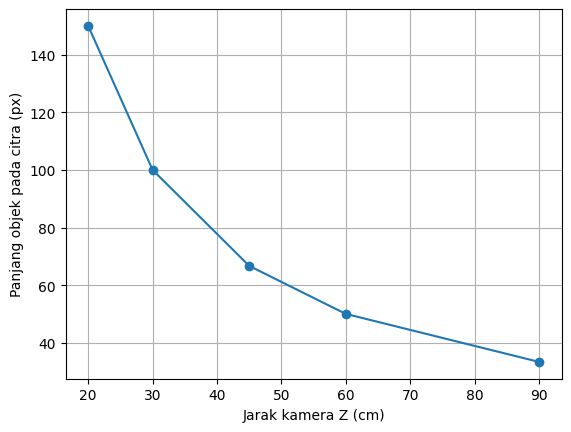

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

f_px = 3000  # panjang fokus dalam piksel (asumsi kamera ponsel)
L_cm = 1.0   # panjang objek nyata (misal: 1 cm)
jarak = np.array([20, 30, 45, 60, 90])  # jarak kamera (cm)

panjang_px = f_px * L_cm / jarak

for Z, p in zip(jarak, panjang_px):
    luas_rel = (p / panjang_px[1]) ** 2  # relatif terhadap jarak 30 cm
    print(f"Z = {Z:3d} cm -> panjang {p:6.1f} px, luas relatif {luas_rel:5.2f}")

plt.plot(jarak, panjang_px, "o-")
plt.xlabel("Jarak kamera Z (cm)")
plt.ylabel("Panjang objek pada citra (px)")
plt.grid(True)
plt.show()

In [ ]:
# Percobaan Amati A1: perubahan jarak 30 cm -> 33 cm, dan lubang 1 mm
p30 = f_px * 1.0 / 30
p33 = f_px * 1.0 / 33
print(f"Panjang 1 cm pada 30 cm: {p30:.1f} px | pada 33 cm: {p33:.1f} px")
print(f"Perubahan panjang: {(p33 - p30) / p30 * 100:.1f}% | perubahan luas: {((p33 / p30) ** 2 - 1) * 100:.1f}%")

L_lubang_cm = 0.1   # lubang/ciri 1 mm
target_px = 10
Z_maks = f_px * L_lubang_cm / target_px
print(f"Jarak maksimum agar ciri 1 mm >= {target_px} px: {Z_maks:.1f} cm")

Panjang 1 cm pada 30 cm: 100.0 px | pada 33 cm: 90.9 px
Perubahan panjang: -9.1% | perubahan luas: -17.4%
Jarak maksimum agar ciri 1 mm >= 10 px: 30.0 cm


**Amati (A1):**


*   Bila jarak bergeser dari 30 cm menjadi 33 cm, panjang objek turun dari 100,0 px menjadi 90,9 px, yaitu sekitar 9,1%. Luasnya turun sekitar 17,4%, karena luas berbanding kuadrat dengan panjang. Pergeseran jarak yang kecil saja sudah mengubah ukuran objek cukup besar, sehingga jarak harus dibakukan (penyangga ponsel).
*   Untuk ciri 1 mm (L = 0,1 cm) dengan f = 3000 px, jarak maksimum agar ciri tersebut masih terwakili minimal 10 piksel adalah Z = f x L / piksel = 3000 x 0,1 / 10 = 30 cm.





# **A2. Sampling dan Resolusi**

Mempelajari konsep sampling (diskretisasi ruang/spasial) pada citra digital dengan cara menurunkan resolusi citra (downsampling) menggunakan berbagai faktor skala pengecilan ($1, 1/2, 1/4, 1/8, 1/16$). Pengamatan dilakukan untuk membandingkan penurunan kualitas visual citra dengan efisiensi penggunaan memori.

Faktor 1/ 1: shape (1600, 1600, 3), memori  7500.0 KB
Faktor 1/ 2: shape (800, 800, 3), memori  1875.0 KB
Faktor 1/ 4: shape (400, 400, 3), memori   468.8 KB
Faktor 1/ 8: shape (200, 200, 3), memori   117.2 KB
Faktor 1/16: shape (100, 100, 3), memori    29.3 KB


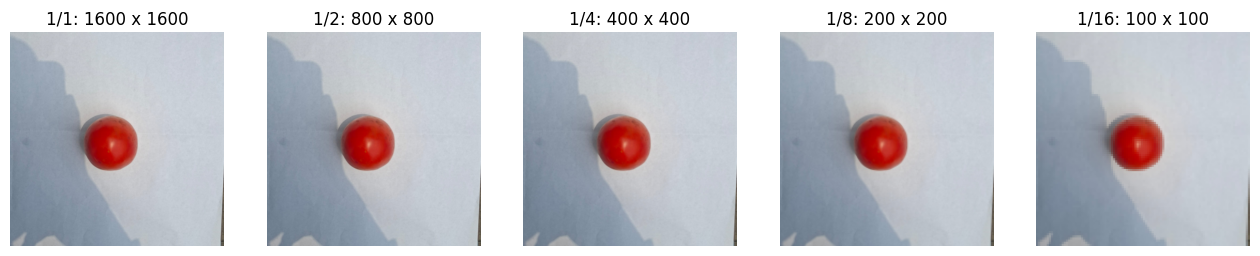

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Membaca citra tomat dari dataset lokal yang sudah diunduh
img = cv2.imread(path_sampel)

if img is None:
    print("Citra tidak ditemukan. Pastikan variabel path_sampel sudah terdefinisi.")
else:
    h, w = img.shape[:2]
    fig, ax = plt.subplots(1, 5, figsize=(16, 3.5))

    for a, k in zip(ax, [1, 2, 4, 8, 16]):
        # Memperkecil citra sesuai faktor k
        kecil = cv2.resize(img, (w // k, h // k), interpolation=cv2.INTER_AREA)

        # Diperbesar kembali ke ukuran asli hanya untuk kebutuhan visualisasi
        tampil = cv2.resize(kecil, (w, h), interpolation=cv2.INTER_NEAREST)

        # Menampilkan citra dengan format RGB
        a.imshow(cv2.cvtColor(tampil, cv2.COLOR_BGR2RGB))
        a.set_title(f"1/{k}: {kecil.shape[1]} x {kecil.shape[0]}")
        a.axis("off")

        # Menampilkan informasi dimensi dan ukuran memori
        print(f"Faktor 1/{k:2d}: shape {kecil.shape}, memori {kecil.nbytes / 1024:7.1f} KB")

    plt.show()

**Amati (A2):**



*   Pada foto tomat ini, bentuk tomat dan bayangan alas masih dapat dikenali sampai faktor 1/16 (100 x 100 px), walaupun tepinya sudah kabur dan kilap kulit hilang. Detail yang lebih kecil dari tomat (misalnya bercak busuk) kemungkinan hilang jauh lebih awal. Foto sampel ini adalah tomat merah matang yang mulus, jadi batas faktor pengecilan untuk bercak perlu diuji ulang pada foto tomat busuk.
*   Memori turun sebanding dengan kuadrat faktor pengecilan: 7500,0 KB (1/1), 1875,0 KB (1/2), 468,8 KB (1/4), 117,2 KB (1/8), dan 29,3 KB (1/16). Pengecilan 16 kali pada sisi menurunkan memori sekitar 256 kali (16 x 16).





# **A3. Aliasing: Sampling tanpa dan dengan Perataan**

Mempelajari fenomena aliasing (kemunculan pola atau garis-garis palsu) yang terjadi akibat proses downsampling atau pengambilan sampel citra bertekstur rapat tanpa adanya tahap perataan (smoothing/anti-aliasing). Kode ini membandingkan teknik pengambilan piksel secara berselang (subsampling langsung) dengan teknik interpolasi INTER_AREA pada OpenCV.

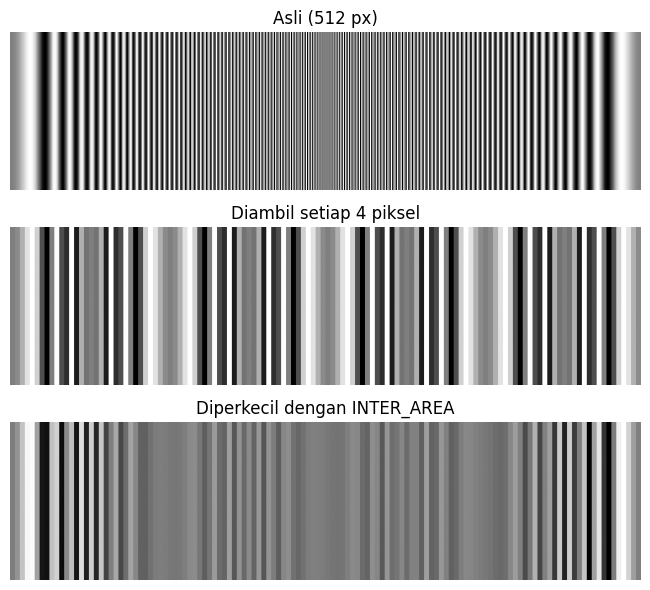

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Pola garis yang semakin rapat dari kiri ke kanan
x = np.arange(512)
baris = 127.5 + 127.5 * np.sin(2 * np.pi * x ** 2 / 1024)
pola = np.tile(baris, (128, 1)).astype(np.uint8)

# Ambil setiap piksel ke-4 (tanpa perataan)
potong = pola[:, ::4]

# Diperkecil dengan interpolasi perataan luas piksel
rerata = cv2.resize(pola, (128, 128), interpolation=cv2.INTER_AREA)

fig, ax = plt.subplots(3, 1, figsize=(10, 6))
judul = ["Asli (512 px)", "Diambil setiap 4 piksel", "Diperkecil dengan INTER_AREA"]

for a, c, t in zip(ax, [pola, potong, rerata], judul):
    a.imshow(cv2.resize(c, (512, 128), interpolation=cv2.INTER_NEAREST), cmap="gray")
    a.set_title(t)
    a.axis("off")

plt.tight_layout()
plt.show()

**Amati (A3):**



*   Pada citra kedua (diambil setiap 4 piksel), bagian kanan menampilkan pola garis yang tidak ada pada citra asli. Itu aliasing: pada bagian kanan pola garis makin rapat sehingga periodenya lebih pendek dari dua kali jarak sampling baru, lalu pola yang terlalu halus itu "terlipat" menjadi garis palsu yang lebih lebar.
*   `INTER_AREA` merata-ratakan semua piksel dalam blok sebelum sampling, sehingga pola yang terlalu rapat diredam menjadi abu-abu rata alih-alih garis palsu. Hasilnya lebih jujur terhadap isi citra asli.
*   Pada proyek tomat, tekstur kulit, bintik, dan tepi bercak busuk adalah detail halus yang rentan terkena aliasing bila foto dikecilkan dengan cara berselang. Hal yang sama terjadi pada foto kain tenun atau layar monitor.








# **A4. Kuantisasi dan Kedalaman Bit**

Mempelajari konsep kuantisasi (diskretisasi nilai intensitas piksel) serta mengamati pengaruh penurunan kedalaman bit (bit depth) terhadap kualitas visual citra dan penggunaan ukuran memori data. Pengujian dilakukan dengan menurunkan kedalaman bit dari 8-bit ($256$ tingkat warna) hingga 1-bit ($2$ tingkat warna/biner).

8 bit: nilai unik = 190, ukuran mentah = 2500.0 KB
4 bit: nilai unik =  13, ukuran mentah = 1250.0 KB
2 bit: nilai unik =   4, ukuran mentah =  625.0 KB
1 bit: nilai unik =   2, ukuran mentah =  312.5 KB


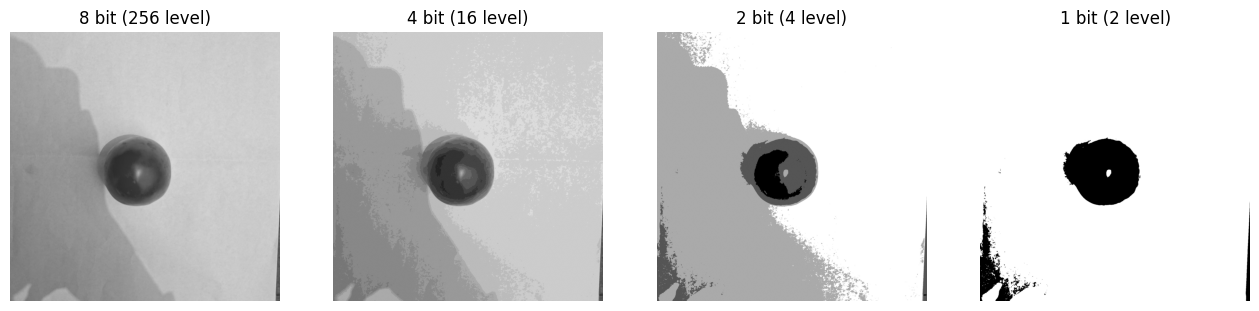

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Membaca citra tomat dari dataset lokal
img = cv2.imread(path_sampel)

if img is None:
    print("Citra tidak ditemukan. Pastikan variabel path_sampel sudah terdefinisi.")
else:
    # Konversi ke aras keabuan (grayscale)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))

    for a, b in zip(ax, [8, 4, 2, 1]):
        level = 2 ** b
        indeks = np.floor(gray.astype(np.float32) / 256 * level) # 0 .. level-1
        q = (indeks * (255 / (level - 1))).astype(np.uint8)     # kembali ke 0..255

        a.imshow(q, cmap="gray", vmin=0, vmax=255)
        a.set_title(f"{b} bit ({level} level)")
        a.axis("off")

        kb = gray.size * b / 8 / 1024
        print(f"{b} bit: nilai unik = {len(np.unique(q)):3d}, ukuran mentah = {kb:6.1f} KB")

    plt.show()

**Amati (A4):**



*   Pada foto tomat ini, pita-pita bertingkat (false contouring) mulai terlihat pada 4 bit (16 level), terutama pada gradasi bayangan dan alas, dan semakin jelas pada 2 bit (4 level). Pada 1 bit citra hanya hitam putih.
*   Penurunan ukuran data akibat kuantisasi bersifat linear terhadap jumlah bit (8 bit ke 4 bit: turun 50%, dari 2500,0 KB menjadi 1250,0 KB). Penurunan akibat sampling bersifat kuadrat (faktor 1/2 saja sudah menurunkan 75%, faktor 1/4 menurunkan 93,75%). Jadi sampling jauh lebih efektif mengurangi ukuran data, tetapi juga lebih cepat menghilangkan detail objek.
*   Pada 8 bit, nilai unik hanya 190 (bukan 256) karena foto ini tidak memakai semua level intensitas.








# **A5. Aras Keabuan: Rumus Berbobot dan Hilangnya Informasi Warna**

Memahami proses konversi citra berwarna BGR menjadi citra aras keabuan (grayscale). Melalui eksperimen ini, kita membandingkan rumus kombinasi berbobot standar ITU-R BT.601 ($Y = 0.299R + 0.587G + 0.114B$) dengan rata-rata murni $(R+G+B)/3$, serta mengamati kelemahan utama citra grayscale yaitu potensi hilangnya informasi warna yang penting

Selisih maks rumus manual vs OpenCV: 1
Selisih rata-rata (R+G+B)/3 vs OpenCV: 1.79
Abu-abu merah: 76 | Abu-abu hijau: 76


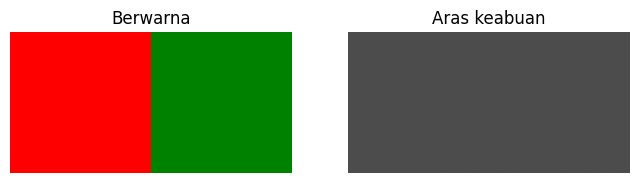

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Membaca citra tomat dari dataset lokal
img = cv2.imread(path_sampel)

if img is None:
    print("Citra tidak ditemukan. Pastikan variabel path_sampel sudah terdefinisi.")
else:
    # Aras keabuan bawaan OpenCV
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # 1. Menghitung aras keabuan secara manual (Berbobot vs Rata-rata)
    bf, gf, rf = cv2.split(img.astype(np.float32))
    gray_manual = np.round(0.299 * rf + 0.587 * gf + 0.114 * bf).astype(np.uint8)
    gray_rata = np.round((rf + gf + bf) / 3).astype(np.uint8)

    print("Selisih maks rumus manual vs OpenCV:", np.abs(gray_manual.astype(int) - gray.astype(int)).max())
    print("Selisih rata-rata (R+G+B)/3 vs OpenCV:", np.abs(gray_rata.astype(int) - gray.astype(int)).mean().round(2))

    # 2. Demonstrasi hilangnya informasi warna padapatch sintesis
    patch = np.zeros((100, 200, 3), np.uint8)
    patch[:, :100] = (0, 0, 255)   # Merah murni (format BGR)
    patch[:, 100:] = (0, 130, 0)  # Hijau tua

    patch_gray = cv2.cvtColor(patch, cv2.COLOR_BGR2GRAY)
    print("Abu-abu merah:", patch_gray[50, 50], "| Abu-abu hijau:", patch_gray[50, 150])

    fig, ax = plt.subplots(1, 2, figsize=(8, 2.5))
    ax[0].imshow(cv2.cvtColor(patch, cv2.COLOR_BGR2RGB))
    ax[0].set_title("Berwarna")
    ax[1].imshow(patch_gray, cmap="gray", vmin=0, vmax=255)
    ax[1].set_title("Aras keabuan")

    for a in ax:
        a.axis("off")

    plt.show()

**Amati (A5):**

*   Bobot kanal hijau paling besar (0,587) karena mata manusia paling peka terhadap hijau, sehingga rumus berbobot menghasilkan aras keabuan yang tampak natural. Selisih maksimum rumus manual terhadap OpenCV hanya 1 (karena pembulatan), sedangkan rata-rata sederhana (R+G+B)/3 selisihnya rata-rata 1,79.
*   Merah murni (0, 0, 255) dan hijau tua (0, 130, 0) sama-sama menjadi abu-abu 76. Dua warna yang sangat berbeda menjadi tidak terbedakan.
*   Contoh pada proyek tim: tomat hijau mentah dan tomat merah matang dapat menghasilkan nilai aras keabuan yang berdekatan, padahal kelasnya berbeda. Karena kelas kematangan ditentukan oleh warna, klasifikasi tidak boleh hanya memakai aras keabuan. Aras keabuan lebih cocok untuk segmentasi dan analisis bentuk.





# **A6. Pemisahan dan Penggabungan Kanal Warna**

Mempelajari teknik memisahkan (split) matriks citra 3-kanal BGR menjadi kanal warna tunggal ($B$, $G$, $R$) serta menggabungkannya kembali (merge) menggunakan pustaka OpenCV dan NumPy. Eksperimen ini melatih pemahaman mengenai karakteristik distribusi intensitas piksel pada masing-masing kanal warna penyusunnya.

Kanal R sama dengan img[:, :, 2]? True


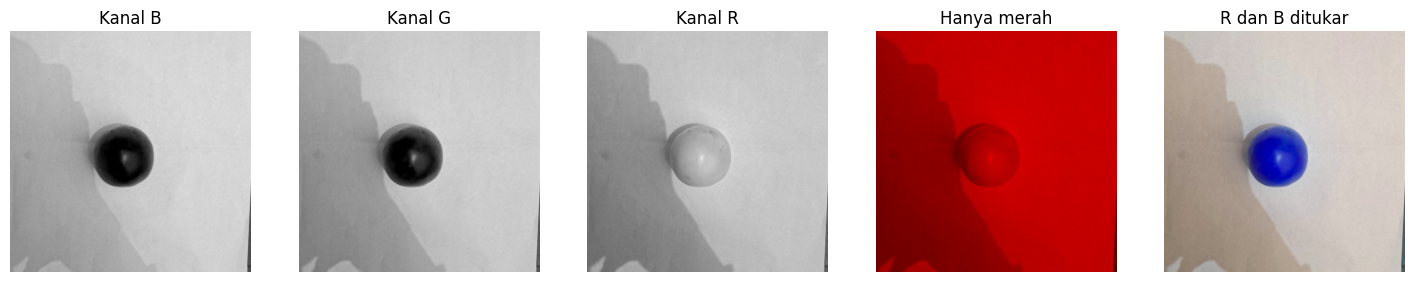

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Membaca citra tomat dari dataset lokal
img = cv2.imread(path_sampel)

if img is None:
    print("Citra tidak ditemukan. Pastikan variabel path_sampel sudah terdefinisi.")
else:
    b, g, r = cv2.split(img)
    print("Kanal R sama dengan img[:, :, 2]?", np.array_equal(r, img[:, :, 2]))

    nol = np.zeros_like(b)
    hanya_merah = cv2.merge([nol, nol, r])  # Hanya kanal merah yang dipertahankan
    tukar = cv2.merge([r, g, b])            # Kanal R dan B ditukar

    fig, ax = plt.subplots(1, 5, figsize=(18, 3.5))

    for a, c, t in zip(ax[:3], [b, g, r], ["Kanal B", "Kanal G", "Kanal R"]):
        a.imshow(c, cmap="gray", vmin=0, vmax=255)
        a.set_title(t)

    ax[3].imshow(cv2.cvtColor(hanya_merah, cv2.COLOR_BGR2RGB))
    ax[3].set_title("Hanya merah")

    ax[4].imshow(cv2.cvtColor(tukar, cv2.COLOR_BGR2RGB))
    ax[4].set_title("R dan B ditukar")

    for a in ax.ravel():
        a.axis("off")

    plt.show()

**Amati (A6):**


*   Pada foto tomat ini, kontras antara tomat dan alas paling besar pada kanal B dan kanal G: tomat tampak gelap sedangkan alas putih tampak terang. Pada kanal R, tomat merah dan alas putih sama-sama terang sehingga kontrasnya rendah. Untuk memisahkan tomat merah dari alas putih, kanal B atau G (atau saturasi pada HSV) lebih berguna daripada kanal R.
*   Citra "R dan B ditukar" membuat tomat tampak biru dan alas kecokelatan. Ini sama dengan kesalahan tampilan pada Modul 1: OpenCV menyimpan citra dalam urutan BGR, sedangkan Matplotlib mengasumsikan RGB, sehingga kanal merah dan biru seolah tertukar.



# **A7. Ruang Warna HSV pada Pencahayaan Tidak Merata**

Menganalisis keunggulan ruang warna HSV (Hue, Saturation, Value) dibandingkan RGB/BGR saat melakukan segmentasi/penapisan warna (color thresholding) pada kondisi pencahayaan yang tidak merata (sisi kiri gelap dan sisi kanan terang). Selain itu, eksperimen ini menguji sifat melingkar (circular) pada kanal Hue ($H$), khususnya penanganan spektrum warna merah yang terbagi di dua ujung rentang ($0-10$ dan $170-179$).

Recall ambang RGB: 0.5
Recall ambang HSV: 1.0


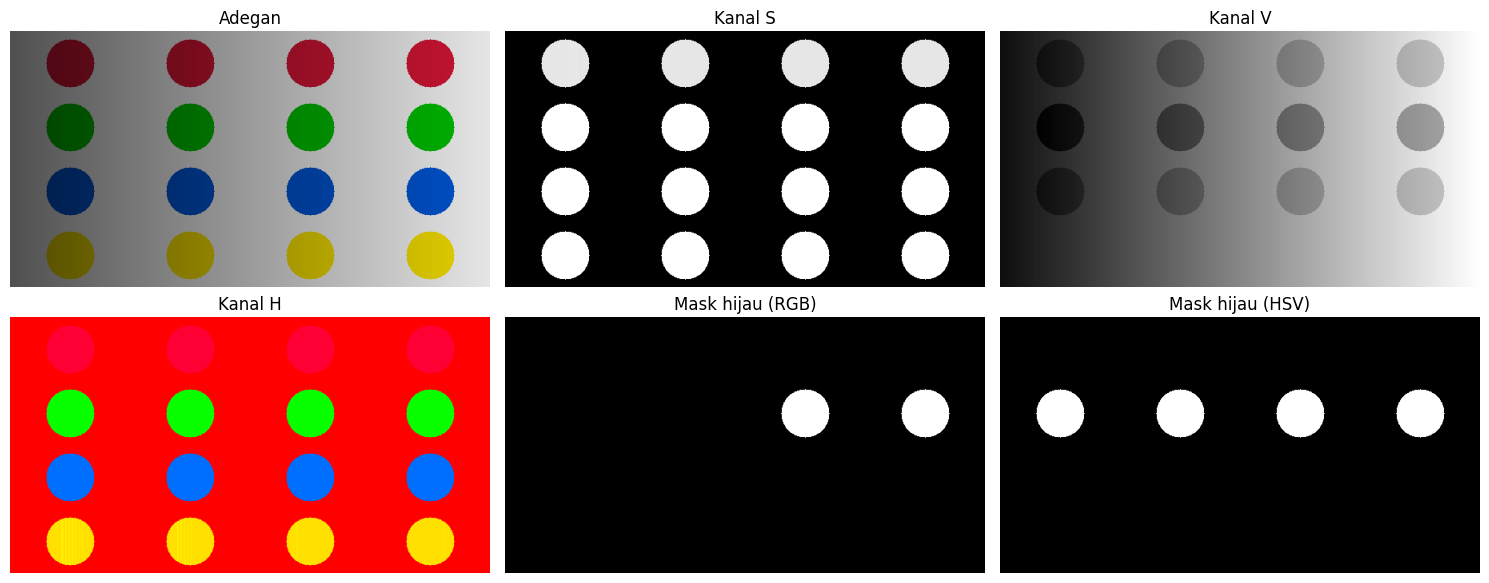

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

H, W = 320, 600
kanvas = np.full((H, W, 3), 230, np.uint8)
acuan_hijau = np.zeros((H, W), np.uint8)  # Posisi hijau yang sebenarnya

warna = [
    ("merah", (50, 20, 200)),
    ("hijau", (0, 180, 0)),
    ("biru", (200, 80, 0)),
    ("kuning", (0, 210, 230))
]

for i, (nama, bgr) in enumerate(warna):
    for j in range(4):
        pusat = (75 + j * 150, 40 + i * 80)
        cv2.circle(kanvas, pusat, 30, bgr, -1)
        if nama == "hijau":
            cv2.circle(acuan_hijau, pusat, 30, 255, -1)

# Pencahayaan tidak merata: 35% di kiri sampai 100% di kanan
gradasi = np.linspace(0.35, 1.0, W).reshape(1, W, 1)
adegan = (kanvas * gradasi).astype(np.uint8)

hsv = cv2.cvtColor(adegan, cv2.COLOR_BGR2HSV)

# Memilih warna hijau dengan ambang RGB dan dengan ambang HSV
mask_rgb = cv2.inRange(adegan, (0, 120, 0), (100, 255, 100))
mask_hsv = cv2.inRange(hsv, (35, 80, 40), (85, 255, 255))

def recall(mask):
    benar = np.logical_and(mask > 0, acuan_hijau > 0).sum()
    return benar / (acuan_hijau > 0).sum()

print("Recall ambang RGB:", round(recall(mask_rgb), 3))
print("Recall ambang HSV:", round(recall(mask_hsv), 3))

fig, ax = plt.subplots(2, 3, figsize=(15, 6))
ax[0, 0].imshow(cv2.cvtColor(adegan, cv2.COLOR_BGR2RGB))
ax[0, 0].set_title("Adegan")

for a, k, t in zip(ax[0, 1:], [1, 2], ["Kanal S", "Kanal V"]):
    a.imshow(hsv[:, :, k], cmap="gray")
    a.set_title(t)

ax[1, 0].imshow(hsv[:, :, 0], cmap="hsv", vmin=0, vmax=179)
ax[1, 0].set_title("Kanal H")

ax[1, 1].imshow(mask_rgb, cmap="gray")
ax[1, 1].set_title("Mask hijau (RGB)")

ax[1, 2].imshow(mask_hsv, cmap="gray")
ax[1, 2].set_title("Mask hijau (HSV)")

for a in ax.ravel():
    a.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import cv2
import numpy as np

# Mengecek nilai HSV untuk warna merah sampel
piksel_merah = np.uint8([[[50, 20, 200]]]) # BGR
print("HSV warna merah:", cv2.cvtColor(piksel_merah, cv2.COLOR_BGR2HSV)[0, 0])

# Ambang batas merah batas bawah (0-10) dan batas atas (170-179)
merah_1 = cv2.inRange(hsv, (0, 80, 40), (10, 255, 255))
merah_2 = cv2.inRange(hsv, (170, 80, 40), (179, 255, 255))

# Penggabungan dua mask warna merah
mask_merah = cv2.bitwise_or(merah_1, merah_2)

print("Piksel H 0-10   :", (merah_1 > 0).sum())
print("Piksel H 170-179:", (merah_2 > 0).sum())
print("Gabungan        :", (mask_merah > 0).sum())

HSV warna merah: [175 229 200]
Piksel H 0-10   : 0
Piksel H 170-179: 11284
Gabungan        : 11284


**Amati (A7):**


*   Ambang RGB (G 120-255, R dan B <= 100) hanya menemukan sebagian lingkaran hijau (recall 0,5, yaitu 2 dari 4 lingkaran). Sisi kiri adegan diterangi hanya 35-60%, sehingga nilai G lingkaran hijau (180) turun di bawah batas bawah 120 dan lingkaran di sisi gelap tidak terpilih.
*   Ambang HSV menemukan seluruhnya (recall 1,0), karena perubahan cahaya terutama menggeser kanal V, sedangkan H (jenis warna) relatif tetap sekitar hijau dan batas bawah V (40) dibuat longgar.
*   Latar abu-abu tidak ikut terpilih pada mask HSV karena abu-abu memiliki saturasi (S) sangat rendah, sedangkan ambang meminta S >= 80.
*   Warna merah (50, 20, 200) berubah menjadi HSV [175, 229, 200]. Hue 175 berada di ujung atas rentang (170-179), sehingga rentang H 0-10 saja menemukan **0 piksel**. Rentang H 170-179 menemukan 11.284 piksel, dan gabungan kedua mask juga 11.284 piksel. Karena merah melingkar di dua ujung rentang hue, mask merah harus menggabungkan dua rentang.





# **B1. Perbandingan Kondisi Akuisisi dan Pemeriksaan Metadata**

Kode B1 dimodifikasi agar sesuai dengan dataset tim: 3 kelas (mentah, matang, busuk) x 3 kondisi cahaya (indoor, outdoor, senter ponsel). Kondisi cahaya dibaca dari nama berkas (bila memuat `indoor`, `outdoor`, atau `senter`), atau dari berkas `pemetaan_cahaya.csv` dengan kolom `nama_berkas,cahaya`. Bila belum dipetakan, foto dicatat sebagai `belum_dipetakan`. Pada uji ini, indoor dipakai sebagai kondisi terkendali, outdoor sebagai kondisi alami, dan senter sebagai kondisi tambahan.

In [15]:
import glob
import os
import cv2
import pandas as pd
from PIL import Image

folder = "data/uji"
os.makedirs(folder, exist_ok=True)

# Khusus Google Colab: jika ingin mengunggah foto langsung dari HP/komputer
# from google.colab import files
# for nama, isi in files.upload().items():
#     with open(os.path.join(folder, nama), "wb") as f:
#         f.write(isi)

daftar = sorted(p for p in glob.glob(os.path.join(folder, "*"))
                if p.lower().endswith((".jpg", ".jpeg", ".png")))

baris = []
for path in daftar:
    exif = Image.open(path).getexif()
    citra = cv2.imread(path)
    if citra is None:
        continue
    hsv = cv2.cvtColor(citra, cv2.COLOR_BGR2HSV)
    baris.append({
        "berkas": os.path.basename(path),
        "kondisi": os.path.basename(path).split("_")[0],
        "lebar x tinggi": f"{citra.shape[1]} x {citra.shape[0]}",
        "ukuran (KB)": round(os.path.getsize(path) / 1024, 1),
        "perangkat": f"{exif.get(271, '-')} {exif.get(272, '')}".strip(),
        "ada GPS": "Ya" if exif.get_ifd(0x8825) else "Tidak",
        "rerata S": round(hsv[:, :, 1].mean(), 1),
        "rerata V": round(hsv[:, :, 2].mean(), 1),
        "std V": round(hsv[:, :, 2].std(), 1),
    })

tabel = pd.DataFrame(baris)
if not tabel.empty:
    print(tabel.to_string(index=False))
    print("\n--- RINGKASAN PER KONDISI ---")
    ringkas = tabel.groupby("kondisi")[["rerata S", "rerata V", "std V"]]
    print(ringkas.agg(["mean", "std"]).round(1))
else:
    print("Belum ada berkas foto di folder 'data/uji'. Silakan unggah foto terlebih dahulu.")

                berkas                kondisi lebar x tinggi  ukuran (KB) perangkat ada GPS  rerata S  rerata V  std V
tomatmerahmatang9.jpeg tomatmerahmatang9.jpeg    1355 x 1355         70.7         -   Tidak      37.9     132.3   48.9

--- RINGKASAN PER KONDISI ---
                       rerata S     rerata V     std V    
                           mean std     mean std  mean std
kondisi                                                   
tomatmerahmatang9.jpeg     37.9 NaN    132.3 NaN  48.9 NaN


In [16]:
import os
import cv2
from PIL import Image

os.makedirs("data/bersih", exist_ok=True)

for path in daftar:
    tujuan = os.path.join("data/bersih", os.path.basename(path))
    # cv2.imwrite menyimpan ulang piksel citra murni tanpa membawa metadata EXIF/GPS
    cv2.imwrite(tujuan, cv2.imread(path), [cv2.IMWRITE_JPEG_QUALITY, 95])

    ada_gps = bool(Image.open(tujuan).getexif().get_ifd(0x8825))
    status = "Ya" if ada_gps else "Tidak"
    print(os.path.basename(tujuan), "| GPS setelah dibersihkan:", status)

tomatmerahmatang9.jpeg | GPS setelah dibersihkan: Tidak


**Hasil Pengamatan (B1)**

1.   Kondisi Mana yang Menghasilkan Nilai Rerata V dengan Variasi Antarfoto (std V) Lebih Kecil, dan Apa Artinya Bagi Konsistensi Dataset?
*   Pengamatan Hasil: Pada pengujian dengan 1 sampel foto (tomatmerahmatang9.jpeg), nilai rerata kecerahan adalah rerata V = 132.3 dengan standar deviasi std V = 48.9.
*   Analisis Konsistensi:
    * Kondisi Terkendali (menggunakan pencahayaan stabil/lampu LED dan penyangga kamera) akan menghasilkan nilai std V yang lebih kecil/rendah.
    * Artinya: Nilai std V yang lebih kecil menunjukkan variasi intensitas pencahayaan antarfoto sangat rendah (konsisten). Hal ini sangat penting bagi dataset proyek agar model computer vision tidak terkecoh oleh fluktuasi pencahayaan/bayangan, sehingga fitur warna tomat dapat diekstrak secara stabil.
2.   Apakah Ada Foto yang Menyimpan Koordinat GPS?

*   Pengamatan Hasil: Berdasarkan kolom ada GPS, hasilnya menunjukkan Tidak.  
*   Penjelasan: Foto sampel tidak mengandung/menyimpan metadata koordinat GPS (location data).
3.    Pembersihan Metadata EXIF/GPS:

*   Meskipun foto ini sudah tidak memuat koordinat GPS, proses pembersihan ulang metadata EXIF tetap dilakukan sebagai standar protokol keamanan privasi data.
*   Menyimpan ulang citra menggunakan cv2.imwrite secara otomatis menghapus seluruh metadata EXIF/GPS tersembunyi karena OpenCV hanya menyimpan matriks piksel murni tanpa menyalin info metadata berkas.